# 46 · 생성 규칙과 KV cache

같은 과일 언어모델에서도 매번 가장 큰 확률을 고를지, 여러 후보에서 뽑을지에 따라 문장이 달라집니다. 이미 읽은 앞부분을 매번 다시 계산하는 비용도 줄일 수 있습니다. **생성 분포를 바꾸는 일**과 **같은 계산을 재사용하는 일**을 구분하겠습니다.

- 준비물: [44 토큰 데이터](44_tokenization.ipynb)의 EOS·분모, [45 전체 decoder](45_decoder_gpt.ipynb)의 causal attention·학습 위치·forward/backward, [27 Monte Carlo](../04_생성/27_monte_carlo_gradients.ipynb)의 표본 추출입니다.
- 순서: ① temperature·표본 추출 → ② top-k/top-p → ③ 독립 학습과 prefill → ④ 새 token의 KV cache → ⑤ 실제 생성·동등성·비용입니다.
- 실행: 45번과 같은 작은 모델을 **이 노트북 안에서 처음부터 학습**합니다. 외부 notebook의 실행 상태나 저장 가중치를 읽지 않습니다. cache는 한 head·한 block·단일 문서·padding 없는 한 stream으로 한정합니다.

> **용어** · **temperature**는 logits를 나누는 양수로, sampling 분포의 뾰족함을 조절합니다. **KV cache**는 과거 token의 key·value를 저장해 재사용하는 배열입니다. **prefill**은 처음 주어진 prefix 전체를 처리해 cache를 채우는 단계입니다. **sampling**은 정한 확률에 따라 무작위 token을 뽑는 과정입니다.

### 읽는 법

| 표시 | 확인할 것 |
|---|---|
| 🔑 핵심 | 수식·분포·cache의 의미 |
| 🔍 확인 | 경계·실행 결과·측정 한계 |
| 📎 참고 | 독립 실행 코드·출처 |
| ✏️ 연습 | 한두 줄 재구성 |

**이 노트북에서 반드시 가져갈 세 가지**

1. temperature·top-k·top-p는 학습된 모델의 logits에서 새 생성 정책을 만듭니다.
2. 고정 가중치·위치·causal 규칙에서는 cache와 전체 재계산의 logits가 같습니다.
3. 같은 난수를 써서 생성 결과를 대조하고, 연산량·K/V 메모리·실제 시간을 구분합니다.

[그림 보조 코드](../../src/utils/generation_kv_cache_plots.py) · [학습 경로](../../docs/CURRICULUM.md)

In [1]:
# 준비 셀: 독립 실행을 위한 도구입니다.
import sys
from pathlib import Path
from time import perf_counter
import numpy as np
project_root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0,str(project_root))
from src.utils import setup_plots,run_check
from src.utils.gradcheck import numerical_gradient
from src.utils.generation_kv_cache_plots import (
    plot_temperature,plot_truncation,plot_prefill,plot_cached_step,plot_cache_budget,plot_cache_timing,
)
setup_plots()

'Arial Unicode MS'

## 🔑 1. 같은 logits에서 다른 생성 분포를 만듭니다

**이 절에서 가져갈 것:** temperature는 순위를 보존하면서 분포를 바꾸고, sampling은 누적확률 구간으로 구현할 수 있습니다.

다음 과일 이름 후보의 점수가 `[2,1,0]`이라 합시다. 항상 첫 후보를 고르는 greedy와, 세 후보의 확률에 따라 뽑는 것은 다른 정책입니다.

$$p_i(\tau)=\frac{\exp((s_i-\max_j s_j)/\tau)}{\sum_j\exp((s_j-\max_k s_k)/\tau)},\quad\tau>0.$$

낮은 temperature는 높은 점수에 더 몰리고, 높은 값은 평평해집니다. τ=0은 나눗셈으로 정의하지 않습니다. greedy가 필요하면 argmax 또는 top-k=1을 씁니다. 동점에서는 번호가 작은 것을 먼저 두는 고정 순서를 사용합니다.

범주 추출은 $u\sim Uniform[0,1)$을 뽑아 누적확률이 u를 **처음 초과**하는 칸을 고릅니다. 확률 `(0.25,0.75)`에서 u=.1은 첫째, u=.25는 둘째입니다. 영확률 앞부분은 u=0일 때도 뽑히면 안 됩니다.

> **코드** · `np.searchsorted(cumulative,u,side='right')`는 u와 같은 경계를 오른쪽으로 넘깁니다. `np.cumsum`은 누적합입니다. `np.stack`은 여러 temperature의 분포를 행으로 모읍니다.

In [2]:
temperature_logits=np.array([2.,1.,0.])
temperatures=[.5,1.,2.]
temperature_rows=[]
for temperature in temperatures:
    exponential=np.exp((temperature_logits-temperature_logits.max())/temperature)
    temperature_rows.append(exponential/exponential.sum())
temperature_rows=np.stack(temperature_rows)

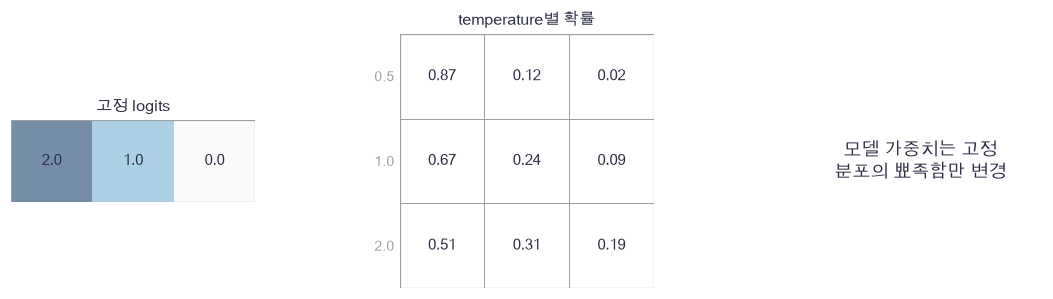

In [3]:
plot_temperature(temperature_logits,temperature_rows,temperatures)

🔍 **확인** · 가장 큰 확률의 위치는 그대로지만 나머지 후보를 뽑을 가능성이 달라집니다. 이 변화는 모델 가중치를 다시 학습한 결과가 아닙니다. 다음 함수는 이미 계산된 확률과 외부에서 전달한 u를 사용하므로 두 구현에 같은 난수를 줄 수 있습니다.

In [4]:
def categorical_sample(probabilities, uniform):
    """고정 u∈[0,1)의 역누적 확률로 한 token을 뽑습니다. 0확률 앞 경계를 건너뜁니다."""
    assert 0<=uniform<1, 'uniform은0이상1미만이어야 합니다'
    assert np.all(probabilities>=0), '확률은 음수가 아니어야 합니다'
    assert np.isclose(probabilities.sum(),1), '확률 합은1이어야 합니다'
    cumulative=np.cumsum(probabilities)
    cumulative[-1]=1.
    return int(np.searchsorted(cumulative,uniform,side='right'))

In [5]:
assert categorical_sample(np.array([.25,.75]),.1)==0, '첫 구간 안의 u는 첫 후보입니다'
assert categorical_sample(np.array([.25,.75]),.25)==1, '경계값은 다음 구간으로 갑니다'
assert categorical_sample(np.array([0.,0.,1.]),0.)==2, '영확률 후보를 뽑으면 안 됩니다'
assert categorical_sample(np.array([.5,.5]),np.nextafter(1.,0.))==1, '1직전 값은 마지막 구간입니다'
print('범주 추출의 손계산·경계·영확률 검산 통과')

범주 추출의 손계산·경계·영확률 검산 통과


### ✏️ 연습 1 · 누적확률을 만들기

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

probabilities의 누적확률 cumulative를 채우세요.

In [6]:
def exercise_cdf(probabilities):
    """누적확률을 만들기의 계산을 완성합니다."""
    ### 구현할 내용: probabilities의 누적확률 cumulative를 채우세요.
    raise NotImplementedError
    return cumulative

In [7]:
def check_cdf(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_allclose(candidate(np.array([.2,.3,.5])),[.2,.5,1.])  # 검산: 확률 구간의 오른쪽 끝
    print("연습 1 통과")

run_check(check_cdf, exercise_cdf, hint="누적확률을 만들기의 수식과 축을 확인하세요.")

☐ exercise_cdf: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 누적확률을 만들기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
cumulative = np.cumsum(probabilities)
```

</details>

## 🔑 2. top-k와 top-p는 남길 후보를 다르게 정합니다

**이 절에서 가져갈 것:** 후보를 고른 뒤 다시 정규화하고, top-p를 처음 넘기는 token도 포함합니다.

확률이 `[.5,.3,.15,.05]`라면 top-k=2는 첫 두 후보를 남깁니다. top-p=.7도 누적확률이 .5→.8로 처음 .7을 넘기는 **두 번째 후보까지** 남깁니다. 첫째만 남기면 요청한 질량을 채우지 못합니다.

확률 내림차순 순서 π에서 $j_\star=\min\{j:\sum_{i\le j}p_{\pi_i}\ge p_\star\}$까지 남깁니다. 남긴 확률의 합으로 다시 나눕니다. 동점은 원래 ID순서로 정합니다.

이 구현의 순서는 **PAD/BOS 금지 → temperature → top-k → top-p → 재정규화**입니다. top-p는 top-k를 적용한 분포 위에서 계산합니다. 두 연산은 순서가 달라지면 다른 정책이 될 수 있습니다.

> **용어** · **top-k**는 상위 k개 후보를, **top-p(nucleus)**는 목표 누적확률을 채우는 최소 앞부분을 남기는 규칙입니다. [Holtzman 외 원문](https://arxiv.org/abs/1904.09751)이 nucleus sampling을 설명합니다. 아래 작은 실험은 그 논문의 자연어 품질 실험을 재현하는 것이 아닙니다.
>
> **코드** · `np.argsort(-p,kind='stable')`는 확률 내림차순이며 동률의 기존 순서를 보존합니다. `cumulative-p_sorted < top_p`는 현재 token **이전** 질량이 임계값 아래인지 검사하므로 경계를 채우는 token을 포함합니다.

In [8]:
truncation_original=np.array([.5,.3,.15,.05])
truncation_cumulative=np.cumsum(truncation_original)
truncation_keep=(truncation_cumulative-truncation_original)<.7
truncation_filtered=truncation_original*truncation_keep
truncation_filtered/=truncation_filtered.sum()

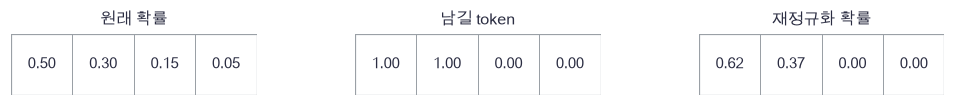

In [9]:
plot_truncation(truncation_original,truncation_keep,truncation_filtered)

🔍 **확인** · 원래 .5/.3이던 두 후보는 합.8로 나누어 .625/.375가 됩니다. 제거한 후보의 확률은0입니다. 아래 함수는 입력 logits를 복사하므로 생성 규칙을 적용해도 모델의 원래 점수 배열을 바꾸지 않습니다.

In [10]:
def sampling_distribution(logits, temperature=1., top_k=None, top_p=1., forbidden=(0,1)):
    """금지 token→temperature→top-k→top-p 순서로 분포를 만들고 다시 정규화합니다."""
    assert np.isfinite(temperature) and temperature>0, 'temperature는 양의 유한수여야 합니다'
    assert 0<top_p<=1, 'top-p는0보다 크고1이하여야 합니다'
    scores=np.array(logits,dtype=float,copy=True)
    scores[list(forbidden)]=-np.inf
    assert not np.isnan(scores).any(), 'NaN 점수는 허용하지 않습니다'
    assert not np.isposinf(scores).any(), '양의 무한대 점수는 허용하지 않습니다'
    allowed=np.isfinite(scores)
    assert allowed.any(), '적어도 하나의 유한한 허용 점수가 필요합니다'
    scores=(scores-np.max(scores[allowed]))/temperature
    probabilities=np.exp(scores)
    if top_k is not None:
        assert isinstance(top_k,int) and 1<=top_k<=len(scores), 'top-k는1부터어휘크기까지의 정수입니다'
        order=np.argsort(-probabilities,kind='stable')
        keep=np.zeros(len(scores),dtype=bool)
        keep[order[:top_k]]=True
        probabilities[~keep]=0
    probabilities/=probabilities.sum()
    order=np.argsort(-probabilities,kind='stable')
    cumulative=np.cumsum(probabilities[order])
    keep_rank=(cumulative-probabilities[order])<top_p
    keep=np.zeros(len(scores),dtype=bool)
    keep[order[keep_rank]]=True
    probabilities[~keep]=0
    return probabilities/probabilities.sum()

In [11]:
np.testing.assert_allclose(sampling_distribution(np.log(truncation_original),top_p=.7,forbidden=()),truncation_filtered)  # 검산: top-p 손계산
np.testing.assert_allclose(sampling_distribution(np.log(truncation_original),top_p=.5,forbidden=()),[1,0,0,0])  # 검산: 경계에 정확히 도달하면 추가 token 불필요
np.testing.assert_allclose(sampling_distribution(np.array([1000.,-1000.,0.]),forbidden=()),[1,0,0])  # 검산: 극단 logits의 안정성
np.testing.assert_allclose(sampling_distribution(np.zeros(4),top_k=1,forbidden=()),[1,0,0,0])  # 검산: 동률 top1은 가장 작은ID
policy=sampling_distribution(np.array([100.,90.,2.,1.]))
assert policy[0]==0, 'PAD는 금지합니다'
assert policy[1]==0, 'BOS는 금지합니다'
assert np.isclose(policy.sum(),1), '금지·절단 뒤에도 확률합은1입니다'
print('top-p 경계·극단 logits·동률·금지 token 검산 통과')

top-p 경계·극단 logits·동률·금지 token 검산 통과


### ✏️ 연습 2 · 남긴 후보의 확률 다시 맞추기

p와 keep을 곱한 뒤 합1인 result를 채우세요.

In [12]:
def exercise_renorm(p, keep):
    """남긴 후보의 확률 다시 맞추기의 계산을 완성합니다."""
    result = p * keep
    ### 구현할 내용: p와 keep을 곱한 뒤 합1인 result를 채우세요.
    raise NotImplementedError
    return result

In [13]:
def check_renorm(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_allclose(candidate(np.array([.5,.3,.2]),np.array([1,1,0])),[.625,.375,0])  # 검산: 남은 질량.8로 나누기
    print("연습 2 통과")

run_check(check_renorm, exercise_renorm, hint="남긴 후보의 확률 다시 맞추기의 수식과 축을 확인하세요.")

☐ exercise_renorm: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 남긴 후보의 확률 다시 맞추기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
result = result / result.sum()
```

</details>

## 🔑 3. prefix 전체를 처리해 K와 V를 저장합니다

**이 절에서 가져갈 것:** prefill은 각 prefix 위치의 정규화된 특성에서 K/V를 만들고 다음 위치 번호를 남깁니다.

`gold`까지 이미 주어졌다면 그 안의 모든 token을 한 번 처리합니다. 한 block의 첫 LN 출력 $U:(T,D)$에서 $K=UW_K$, $V=UW_V$를 저장합니다. Q도 prefix 출력 계산에는 필요하지만 미래 query가 읽는 과거 자료는 K/V입니다.

$$X_t=E[u_t]+P_t,\quad U_t=LN(X_t),\quad K_{1:T}=U_{1:T}W_K,\quad V_{1:T}=U_{1:T}W_V.$$

각 token의 LN은 feature축에서만 계산하고 causal attention은 미래를 보지 않습니다. 따라서 **가중치·위치·prefix가 고정**되면 새 token을 붙여도 과거 K/V를 바꿀 필요가 없습니다. 모델 파라미터를 갱신하거나 prefix·위치를 바꾸면 기존 cache는 버려야 합니다. dropout은 이 모형에 없습니다.

> **용어** · **cache 무효화**는 저장값의 전제가 바뀌어 다시 계산해야 하는 상황입니다. 여러 block이면 block마다 K/V를 저장해야 합니다. 여기서는 한 block뿐입니다.
>
> **코드** · `.copy()`는 기존 배열과 별도의 사본입니다. `cache['position']`에는 다음 token이 쓸 절대 위치를 저장합니다. `np.concatenate`는 새 한 행을 과거 행 뒤에 잇습니다.

In [14]:
prefill_x=np.array([[1.,0.,-1.],[.2,.6,-.8],[.4,-.3,.1]])
prefill_center=prefill_x-prefill_x.mean(axis=-1,keepdims=True)
prefill_features=prefill_center/np.sqrt(np.mean(prefill_center**2,axis=-1,keepdims=True)+1e-5)
prefill_k=prefill_features@np.diag([.5,.7,.3])
prefill_v=prefill_features@np.array([[1.,0.],[0.,1.],[.2,.2]])

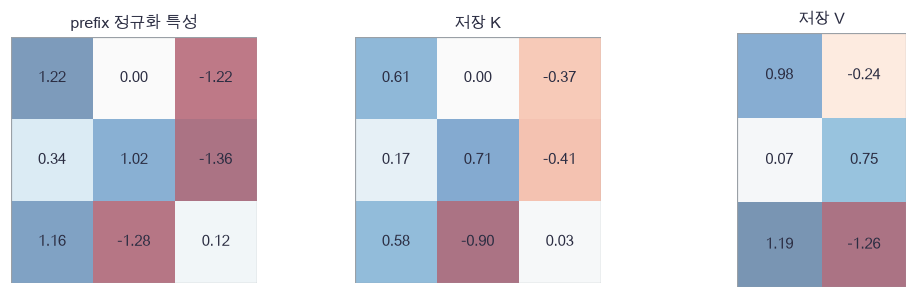

In [15]:
plot_prefill(prefill_features,prefill_k,prefill_v)

🔍 **확인** · 각 행이 prefix의 한 위치입니다. 그림의 K와 V는 설명용 작은 배열이며 실제 모형에서는 둘 다 `(T,D)`입니다. 아래에는45번의 전체 모델·미분·CE·Adam·학습을 다시 둡니다. 이 복습 부분은 cache 계산을 숨긴 helper가 아니며, 새 커널에서 모델을 실제 학습하는 데 사용합니다.

구조는 한 pre-LN block $X+Attention(LN(X))$와 $R+\tanh(LN(R)W_1+c_1)W_2+c_2$, 최종 LN·head입니다. E:(V,D), P:(32,D), D=12, FFN폭24입니다. 손실은 유효 next-token 평균 CE이고 Adam은 학습률.01·모멘트.9/.999·300회입니다. 앞 단원의 같은 고정 문법·train12/valid2/test2 분할을 재구성합니다.

In [16]:
def masked_softmax(scores, allowed):
    """마지막 key 축에서 허용한 점수만 정규화합니다. 전부 막힌 행은0입니다."""
    masked = np.where(allowed, scores, -np.inf)
    maximum = masked.max(axis=-1, keepdims=True)
    maximum = np.where(np.isfinite(maximum), maximum, 0.)
    exponential = np.exp(masked - maximum)
    total = exponential.sum(axis=-1, keepdims=True)
    return np.divide(exponential, total, out=np.zeros_like(exponential), where=total > 0)

In [17]:
def layernorm_forward(x, gamma, beta, epsilon=1e-5):
    """각 token의 마지막 D축을 정규화하고 affine 변환합니다."""
    centered = x - x.mean(axis=-1, keepdims=True)
    inverse = 1 / np.sqrt(np.mean(centered**2, axis=-1, keepdims=True) + epsilon)
    normalized = centered * inverse
    return normalized * gamma + beta, (normalized, inverse, gamma)

In [18]:
def layernorm_backward(upstream, cache):
    """epsilon을 포함한 LayerNorm의 입력·gamma·beta 미분을 반환합니다."""
    normalized, inverse, gamma = cache
    weighted = upstream * gamma
    dx = inverse * (weighted - weighted.mean(axis=-1, keepdims=True)
                    - normalized * (weighted * normalized).mean(axis=-1, keepdims=True))
    axes = tuple(range(upstream.ndim - 1))
    return dx, np.sum(upstream * normalized, axis=axes), np.sum(upstream, axis=axes)

In [19]:
def attention_forward(x, valid, p, causal=True):
    """한 head self-attention. x:(N,T,D), valid:(N,T); query/key padding을 모두 막습니다."""
    q, k, v = x @ p['Wq'], x @ p['Wk'], x @ p['Wv']
    scores = q @ k.swapaxes(-1,-2) / np.sqrt(x.shape[-1])
    allowed = valid[:,:,None] & valid[:,None,:]
    if causal:
        allowed = allowed & np.tril(np.ones((x.shape[1],x.shape[1]),dtype=bool))[None,:,:]
    probabilities = masked_softmax(scores, allowed)
    mixed = probabilities @ v
    return mixed @ p['Wo'], (x,q,k,v,probabilities,mixed)

In [20]:
def attention_backward(upstream, cache, p):
    """attention의 값 경로와 Q/K 점수 경로를 모두 누적합니다."""
    x,q,k,v,probabilities,mixed = cache
    width = x.shape[-1]
    delta = upstream @ p['Wo'].T
    dp = delta @ v.swapaxes(-1,-2)
    dv = probabilities.swapaxes(-1,-2) @ delta
    ds = probabilities * (dp - np.sum(dp * probabilities, axis=-1, keepdims=True))
    dq = (ds @ k) / np.sqrt(width)
    dk = (ds.swapaxes(-1,-2) @ q) / np.sqrt(width)
    flat = x.reshape(-1,width)
    gradients = {'Wo': mixed.reshape(-1,width).T @ upstream.reshape(-1,width),
                 'Wq': flat.T @ dq.reshape(-1,width), 'Wk': flat.T @ dk.reshape(-1,width),
                 'Wv': flat.T @ dv.reshape(-1,width)}
    dx = dq @ p['Wq'].T + dk @ p['Wk'].T + dv @ p['Wv'].T
    return dx, gradients

In [21]:
def init_decoder(vocabulary_size, width=12, hidden=24, max_length=32, seed=45, tied=False):
    """한 pre-LN decoder block과 최종 LN·head를 만듭니다. 모든 배열은 float64입니다."""
    rng = np.random.default_rng(seed)
    p = {'E': rng.normal(0,.15,(vocabulary_size,width)),
         'P': rng.normal(0,.08,(max_length,width))}
    for layer in ['1','2','f']:
        p['g'+layer] = np.ones(width)
        p['b'+layer] = np.zeros(width)
    for name in ['Wq','Wk','Wv','Wo']:
        p[name] = rng.normal(0,.25/np.sqrt(width),(width,width))
    p['W1'] = rng.normal(0,.5/np.sqrt(width),(width,hidden))
    p['c1'] = np.zeros(hidden)
    p['W2'] = rng.normal(0,.5/np.sqrt(hidden),(hidden,width))
    p['c2'] = np.zeros(width)
    if not tied:
        p['head'] = rng.normal(0,.3/np.sqrt(width),(width,vocabulary_size))
    p['bias'] = np.zeros(vocabulary_size)
    return p

In [22]:
def decoder_from_embeddings(x, valid, p, tied=False, causal=True):
    """연속 embedding 입력에서 LN→attention→잔차→LN→FFN→잔차→LN→head입니다."""
    # 쓰는 것: layernorm_forward (앞 절의 정의·실행 셀)
    first, cache1 = layernorm_forward(x,p['g1'],p['b1'])
    attended, attention_cache = attention_forward(first,valid,p,causal)
    residual = x + attended
    second, cache2 = layernorm_forward(residual,p['g2'],p['b2'])
    activation = np.tanh(second @ p['W1'] + p['c1'])
    hidden = residual + activation @ p['W2'] + p['c2']
    final, cachef = layernorm_forward(hidden,p['gf'],p['bf'])
    head = p['E'].T if tied else p['head']
    logits = final @ head + p['bias']
    return logits,(cache1,attention_cache,cache2,second,activation,cachef,final)

In [23]:
def decoder_feature_backward(dlogits, cache, p, tied=False):
    """연속 입력과 모든 block/head 배열을 미분합니다. tied이면 출력 E 경로도 더합니다."""
    # 쓰는 것: layernorm_backward (앞 절의 정의·실행 셀)
    # 1) head와 최종 정규화를 거슬러 갑니다.
    cache1,attention_cache,cache2,second,activation,cachef,final = cache
    width = final.shape[-1]
    gradients = {name:np.zeros_like(value) for name,value in p.items()}
    head_gradient = final.reshape(-1,width).T @ dlogits.reshape(-1,dlogits.shape[-1])
    if tied:
        gradients['E'] += head_gradient.T
        delta = dlogits @ p['E']
    else:
        gradients['head'] = head_gradient
        delta = dlogits @ p['head'].T
    gradients['bias'] = dlogits.sum(axis=(0,1))
    dh,gradients['gf'],gradients['bf'] = layernorm_backward(delta,cachef)
    # 2) FFN 경로와 직접 잔차 경로를 합칩니다.
    gradients['W2'] = activation.reshape(-1,activation.shape[-1]).T @ dh.reshape(-1,width)
    gradients['c2'] = dh.sum(axis=(0,1))
    da = (dh @ p['W2'].T) * (1-activation**2)
    gradients['W1'] = second.reshape(-1,width).T @ da.reshape(-1,da.shape[-1])
    gradients['c1'] = da.sum(axis=(0,1))
    dr,gradients['g2'],gradients['b2'] = layernorm_backward(da @ p['W1'].T,cache2)
    dr += dh
    # 3) attention의 모든 경로와 첫 잔차를 합칩니다.
    du,attention_gradients = attention_backward(dr,attention_cache,p)
    gradients.update(attention_gradients)
    dx,gradients['g1'],gradients['b1'] = layernorm_backward(du,cache1)
    return dx + dr, gradients

In [24]:
def decoder_forward(ids, valid, p, tied=False, causal=True):
    """정수 ID→학습 embedding+절대 위치→decoder. PAD 위치의 입력은0으로 만듭니다."""
    assert ids.shape[1] <= len(p['P']), '학습 위치 표의 최대 길이를 넘을 수 없습니다'
    embedded = (p['E'][ids] + p['P'][:ids.shape[1]]) * valid[:,:,None]
    logits,cache = decoder_from_embeddings(embedded,valid,p,tied,causal)
    return logits,(ids,valid,cache)

In [25]:
def decoder_backward(dlogits, full_cache, p, tied=False):
    """선택된 embedding 반복행과 배치가 공유하는 위치행까지 누적합니다."""
    ids,valid,cache = full_cache
    dx,gradients = decoder_feature_backward(dlogits,cache,p,tied)
    dx *= valid[:,:,None]
    np.add.at(gradients['E'],ids.ravel(),dx.reshape(-1,dx.shape[-1]))
    gradients['P'][:ids.shape[1]] += dx.sum(axis=0)
    return gradients,dx

In [26]:
def token_cross_entropy(logits, targets, weights):
    """선택한 target만 가중 평균합니다. logprob 전체와 정확한 dlogits를 반환합니다."""
    shifted = logits - logits.max(axis=-1,keepdims=True)
    logprob = shifted - np.log(np.exp(shifted).sum(axis=-1,keepdims=True))
    denominator = weights.sum()
    assert denominator > 0, '손실에 포함할 target이 적어도 하나 필요합니다'
    assert np.all(weights >= 0), '손실 가중치는 음수가 아니어야 합니다'
    rows = np.arange(targets.size)
    selected = logprob.reshape(-1,logits.shape[-1])[rows,targets.ravel()].reshape(targets.shape)
    loss = -np.sum(selected * weights) / denominator
    delta = np.exp(logprob).reshape(-1,logits.shape[-1])
    delta[rows,targets.ravel()] -= 1
    delta *= weights.ravel()[:,None] / denominator
    return float(loss),delta.reshape(logits.shape),logprob

In [27]:
def decoder_loss(ids, targets, valid, p, tied=False, weights=None, causal=True):
    """모델 전체와 선택 target CE를 연결합니다. 입력 유효 mask와 loss mask를 구분합니다."""
    logits,cache = decoder_forward(ids,valid,p,tied,causal)
    actual_weights = valid if weights is None else weights * valid
    loss,delta,logprob = token_cross_entropy(logits,targets,actual_weights)
    gradients,dx = decoder_backward(delta,cache,p,tied)
    return loss,gradients,logprob,dx

In [28]:
def adam_state(p):
    """모든 학습 배열에 독립인 Adam 상태를 만듭니다."""
    return {'m':{name:np.zeros_like(value) for name,value in p.items()},
            'v':{name:np.zeros_like(value) for name,value in p.items()},'t':0}

In [29]:
def adam_update(p, gradients, state, learning_rate=.01):
    """Adam의 모멘트와 편향 보정으로 지정된 배열만 갱신합니다."""
    state['t'] += 1
    for name in gradients:
        state['m'][name] = .9*state['m'][name] + .1*gradients[name]
        state['v'][name] = .999*state['v'][name] + .001*gradients[name]**2
        first = state['m'][name]/(1-.9**state['t'])
        second = state['v'][name]/(1-.999**state['t'])
        p[name] -= learning_rate*first/(np.sqrt(second)+1e-8)

In [30]:
def language_batch(documents, pad=0, bos=1, eos=2):
    """정수 문서 목록을 BOS 입력·EOS 타깃으로 이동하고 오른쪽 PAD를 채웁니다."""
    length = max(len(document)+1 for document in documents)
    ids = np.full((len(documents),length),pad,dtype=int)
    targets = np.full_like(ids,pad)
    valid = np.zeros_like(ids,dtype=bool)
    for index,document in enumerate(documents):
        count = len(document)+1
        ids[index,:count] = [bos]+list(document)
        targets[index,:count] = list(document)+[eos]
        valid[index,:count] = True
    return ids,targets,valid

In [31]:
def train_decoder(train_batch, valid_batch, vocabulary_size, seed=45, steps=300, tied=False):
    """고정 300회 미니배치 Adam 후 반환합니다. valid는 기록만 하고 선택하지 않습니다."""
    # 쓰는 것: decoder_loss, init_decoder (앞 절의 정의·실행 셀)
    p = init_decoder(vocabulary_size,seed=seed,tied=tied)
    state = adam_state(p)
    rng = np.random.default_rng(seed+100)
    history = []
    for step in range(steps+1):
        if step % 100 == 0:
            train_loss = decoder_loss(*train_batch,p,tied)[0]
            valid_loss = decoder_loss(*valid_batch,p,tied)[0]
            history.append([step,train_loss,valid_loss])
        if step == steps:
            break
        index = rng.integers(0,len(train_batch[0]),size=8)
        batch = tuple(array[index] for array in train_batch)
        _,gradients,_,_ = decoder_loss(*batch,p,tied)
        adam_update(p,gradients,state)
    return p,np.asarray(history)

In [32]:
# 쓰는 것: decoder_loss (앞 절의 정의·실행 셀)
colors=['red','green','gold','blue']
fruits=['apple','pear','plum','grape']
sentences=[f'{color} {fruit} is {color}.' for color in colors for fruit in fruits]
alphabet=sorted(set('red green gold blue apple pear plum grape is.'))
to_id={character:index+3 for index,character in enumerate(alphabet)}
to_character={value:key for key,value in to_id.items()}
order=np.random.default_rng(4502).permutation(16)
train_texts=[sentences[i] for i in order[:12]]
valid_texts=[sentences[i] for i in order[12:14]]
test_texts=[sentences[i] for i in order[14:]]
train_batch=language_batch([[to_id[c] for c in text] for text in train_texts])
valid_batch=language_batch([[to_id[c] for c in text] for text in valid_texts])
test_batch=language_batch([[to_id[c] for c in text] for text in test_texts])
trained,training_history=train_decoder(train_batch,valid_batch,len(to_id)+3)
print('독립 학습 후 train/valid NLL:',training_history[-1,1:])
print('별도 test NLL:',decoder_loss(*test_batch,trained)[0])

독립 학습 후 train/valid NLL: [0.14731091 0.72304696]
별도 test NLL: 1.0139683526167098


In [33]:
def prefill_cache(prefix, p, tied=False):
    """padding 없는 단일 prefix를 한번에 처리하고 이 block의 K/V·다음 위치를 저장합니다."""
    # 쓰는 것: decoder_forward (앞 절의 정의·실행 셀)
    assert len(prefix)>0, 'prefill에는 한 token 이상 필요합니다'
    assert 0 not in prefix, '이 단일 stream cache 예제는 padding을 받지 않습니다'
    ids=np.array([prefix],dtype=int)
    logits,full_cache=decoder_forward(ids,np.ones_like(ids,dtype=bool),p,tied)
    attention_cache=full_cache[2][1]
    cache={'K':attention_cache[2][0].copy(),'V':attention_cache[3][0].copy(),'position':len(prefix)}
    return logits[0,-1].copy(),cache

In [34]:
# 쓰는 것: decoder_forward (앞 절의 정의·실행 셀)
prefix=[1]+[to_id[c] for c in 'gold']
last_logits,prefix_cache=prefill_cache(prefix,trained)
assert prefix_cache['position']==len(prefix), '다음 위치는 처리한 prefix 길이입니다'
assert prefix_cache['K'].shape==(len(prefix),12), 'K는 prefix 위치×모델폭입니다'
assert prefix_cache['V'].shape==prefix_cache['K'].shape, '이 모형의 K/V 모양은 같습니다'
full_logits,_=decoder_forward(np.array([prefix]),np.ones((1,len(prefix)),dtype=bool),trained)
np.testing.assert_allclose(last_logits,full_logits[0,-1],atol=1e-12)  # 검산: prefill의 마지막 logits = 전체 forward
print('실제 학습 모형의 prefill·위치·K/V shape 검산 통과')

실제 학습 모형의 prefill·위치·K/V shape 검산 통과


### ✏️ 연습 3 · K/V 저장 크기 계산하기

길이 length·폭 width·원소당 itemsize에서 두 배열의 bytes_used를 채우세요.

In [35]:
def exercise_memory(length, width, itemsize):
    """K/V 저장 크기 계산하기의 계산을 완성합니다."""
    ### 구현할 내용: 길이 length·폭 width·원소당 itemsize에서 두 배열의 bytes_used를 채우세요.
    raise NotImplementedError
    return bytes_used

In [36]:
def check_memory(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    assert candidate(5,12,8)==960, 'float64 K/V 두 배열은2×5×12×8 byte입니다'
    print("연습 3 통과")

run_check(check_memory, exercise_memory, hint="K/V 저장 크기 계산하기의 수식과 축을 확인하세요.")

☐ exercise_memory: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: K/V 저장 크기 계산하기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
bytes_used = 2 * length * width * itemsize
```

</details>

## 🔑 4. 새 token의 query 하나만 과거를 읽습니다

**이 절에서 가져갈 것:** 새 위치의 Q/K/V만 계산하고, 과거+새 K/V에 대한 한 행 attention을 수행합니다.

prefix 다음에 공백 한 글자를 붙이면 과거 문자를 다시 embedding하지 않습니다. 새 입력 $x_{T+1}=E[u_{T+1}]+P_{T+1}$로 Q/K/V 한 행을 만들고 K/V만 저장 배열 뒤에 붙입니다.

$$a=q_{T+1}K_{1:T+1}^T/\sqrt D:(1,T+1),\quad
h=\operatorname{softmax}(a)V_{1:T+1}:(1,D).$$

현재 query가 볼 수 있는 것은 모두 과거 또는 자기 자신이므로 이 한 행에는 미래를 막을 칸이 없습니다. 단, 다중 token을 한 번에 추가한다면 그 chunk 내부의 causal mask가 다시 필요합니다. 이 함수는 한 token씩만 받습니다. 생성 wrapper의 prefix는 한 문서의 BOS·본문이며, 마지막이 이미 EOS이면 추가 생성 없이 즉시 종료합니다. 중간 EOS 뒤에 본문이 붙은 prefix와 PAD는 거부합니다. 잔차·FFN·최종 LN·head도 새 위치만 계산합니다.

In [37]:
cache_keys=np.array([[1.,0.],[0.,1.],[1.,1.]])
cache_values=np.array([[1.,2.],[-1.,0.],[.5,.5]])
new_query=np.array([[.5,1.]])
new_scores=new_query@cache_keys.T/np.sqrt(2)
new_weights=np.exp(new_scores-new_scores.max())
new_weights/=new_weights.sum()
new_mixed=new_weights@cache_values

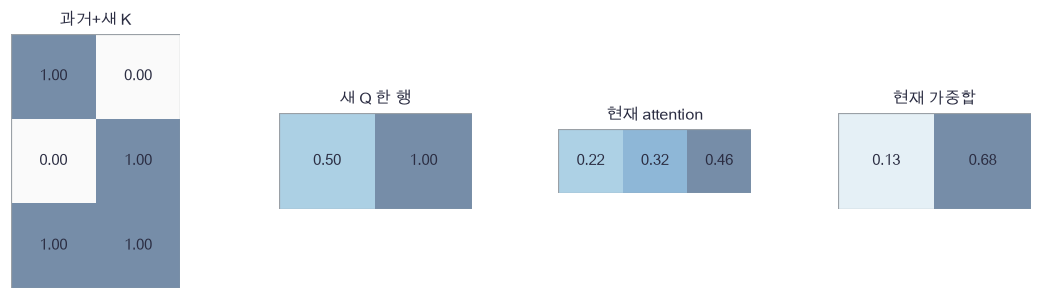

In [38]:
plot_cached_step(cache_keys,new_query,new_weights,new_mixed)

🔍 **확인** · 점수는 `(1,T+1)` 한 행입니다. 새 결과가 과거 token들의 결과를 바꾸지 않는 것은 causal 구조 덕분입니다. 아래 검사는 모델의 모든 어휘 logits를 매 prefix마다 대조하므로 argmax 하나만 우연히 같은 경우를 통과로 보지 않습니다.

In [39]:
def cached_step(token, cache, p, tied=False):
    """새 token 하나의 Q/K/V만 만들고 과거 K/V를 읽어 다음 logits를 계산합니다."""
    # 쓰는 것: layernorm_forward, masked_softmax (앞 절의 정의·실행 셀)
    assert token!=0, '이 단일 stream 예제의 생성 입력은PAD가 아니어야 합니다'
    position=cache['position']
    assert position<len(p['P']), '위치 표 범위를 넘으면 cache도 확장할 수 없습니다'
    x=(p['E'][token]+p['P'][position])[None,:]
    first,_=layernorm_forward(x,p['g1'],p['b1'])
    q=first@p['Wq']
    cache['K']=np.concatenate([cache['K'],first@p['Wk']],axis=0)
    cache['V']=np.concatenate([cache['V'],first@p['Wv']],axis=0)
    scores=q@cache['K'].T/np.sqrt(x.shape[-1])
    probabilities=masked_softmax(scores,np.ones_like(scores,dtype=bool))
    residual=x+(probabilities@cache['V'])@p['Wo']
    second,_=layernorm_forward(residual,p['g2'],p['b2'])
    hidden=residual+np.tanh(second@p['W1']+p['c1'])@p['W2']+p['c2']
    final,_=layernorm_forward(hidden,p['gf'],p['bf'])
    head=p['E'].T if tied else p['head']
    cache['position']+=1
    return (final@head+p['bias'])[0]

In [40]:
def compare_cache_logits(p,tokens,tied=False):
    """매 token의 전체 재계산과 cache logits를 비교하며 K/V 크기도 확인합니다."""
    # 쓰는 것: decoder_forward, prefill_cache (앞 절의 정의·실행 셀)
    logits,cache=prefill_cache(tokens[:1],p,tied)
    errors=[]
    for length in range(1,len(tokens)+1):
        ids=np.array([tokens[:length]])
        expected=decoder_forward(ids,np.ones_like(ids,dtype=bool),p,tied)[0][0,-1]
        errors.append(np.max(np.abs(logits-expected)))
        np.testing.assert_allclose(logits,expected,atol=2e-12,rtol=2e-12)  # 검산: 모든 prefix의 full logits = cache logits
        assert cache['K'].shape==(length,p['E'].shape[1]), 'cache는 처리한 token만 저장해야 합니다'
        if length<len(tokens):
            logits=cached_step(tokens[length],cache,p,tied)
    return max(errors),cache

In [41]:
# 쓰는 것: init_decoder, to_id, trained (앞 절의 정의·실행 셀)
cache_probe=[1]+[to_id[c] for c in 'gold grape is gold.']
maximum_error,checked_cache=compare_cache_logits(trained,cache_probe)
for tied in [False,True]:
    small=init_decoder(7,width=3,hidden=4,max_length=8,seed=4604,tied=tied)
    error,_=compare_cache_logits(small,[1,3,4,3,5,2],tied)
    assert error<2e-12, 'tied/untied 모두cache가 전체계산과 같아야 합니다'
print('학습 모델의 모든 prefix logits 최대 차이:',maximum_error)
print('K/V 실제 byte:',checked_cache['K'].nbytes+checked_cache['V'].nbytes)

학습 모델의 모든 prefix logits 최대 차이: 5.329070518200751e-15
K/V 실제 byte: 3840


In [42]:
def check_repeated_model_gradients():
    """이 독립 notebook의 작은 decoder 모든 배열을 다시 중심차분합니다."""
    # 쓰는 것: decoder_loss, init_decoder (앞 절의 정의·실행 셀)
    p=init_decoder(5,width=3,hidden=4,max_length=4,seed=4605)
    ids=np.array([[1,3,3]])
    targets=np.array([[3,3,2]])
    valid=np.ones_like(ids,dtype=bool)
    _,gradients,_,_=decoder_loss(ids,targets,valid,p)
    def objective():
        """고정 token의 유효 next-token CE입니다."""
        return decoder_loss(ids,targets,valid,p)[0]
    maximum=0.
    for name,value in p.items():
        numeric=numerical_gradient(objective,value)
        np.testing.assert_allclose(gradients[name],numeric,atol=3e-7,rtol=2e-4)  # 검산: 본문 전체 backward = 중심차분
        maximum=max(maximum,float(np.max(np.abs(gradients[name]-numeric))))
    return maximum

In [43]:
print('독립 모델 전체 미분 최대오차:',check_repeated_model_gradients())

독립 모델 전체 미분 최대오차: 2.9358840777590507e-10


### ✏️ 연습 4 · 새 query의 점수 모양

query와 keys로 sqrt(D)를 나눈 scores를 구하세요.

In [44]:
def exercise_query(query, keys):
    """새 query의 점수 모양의 계산을 완성합니다."""
    ### 구현할 내용: query와 keys로 sqrt(D)를 나눈 scores를 구하세요.
    raise NotImplementedError
    return scores

In [45]:
def check_query(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_allclose(candidate(np.array([[1.,0.]]),np.eye(2)),[[1/np.sqrt(2),0.]])  # 검산: 한 query의 두 key 점수
    print("연습 4 통과")

run_check(check_query, exercise_query, hint="새 query의 점수 모양의 수식과 축을 확인하세요.")

☐ exercise_query: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 새 query의 점수 모양의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
scores = query @ keys.T / np.sqrt(query.shape[-1])
```

</details>

## 🔑 5. 같은 난수로 생성하고 비용을 따로 측정합니다

**이 절에서 가져갈 것:** cache는 생성 정책을 바꾸지 않으며, logit·표본 동등성과 시간·메모리를 각각 확인합니다.

같은 모형에 같은 prefix, 같은 temperature/top-k/top-p, 같은 uniform 열을 주면 full/cache 구현이 같은 token을 뽑아야 합니다. 확률 경계에 극도로 가까운 난수에서는 부동소수점 오차로 선택이 달라질 수 있으므로 logits의 오차도 따로 보고합니다.

길이1부터 L까지 매번 full prefix를 계산하면 attention score 원소 수는 $\sum_{t=1}^L t^2$입니다. token 하나씩 cache를 쓰면 $\sum_{t=1}^L t$입니다. 일반 prefill 길이 P에서는 시작 비용 $P^2$ 뒤에 한 행 비용을 더합니다. 이는 **score 원소 수**이며 모델 전체 FLOPs나 시간 자체가 아닙니다.

한 block·한 stream float64의 최종 K/V 저장량은 $2LD\cdot8$ byte입니다. 파라미터·출력 logits·작업 배열·Python 객체·할당 overhead는 이 수치에 포함하지 않습니다. 배열을 매번 이어 붙이는 교육 구현이므로 최적화된 GPU cache와 속도가 같지 않습니다.

In [46]:
budget_lengths=np.array([8,16,24])
full_counts=np.array([np.sum(np.arange(1,length+1)**2) for length in budget_lengths])
cache_counts=np.array([np.sum(np.arange(1,length+1)) for length in budget_lengths])
score_counts=np.stack([full_counts,cache_counts])
cache_bytes=2*budget_lengths*12*8

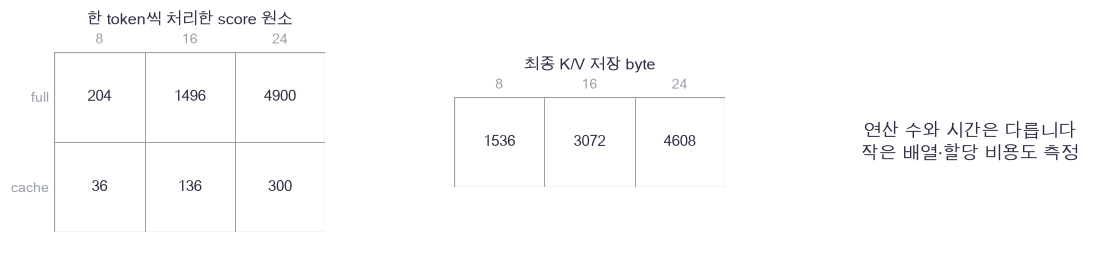

In [47]:
plot_cache_budget(budget_lengths,score_counts,cache_bytes)

🔍 **확인** · 저장 메모리는 길이에 비례해 늘고 score 계산의 반복은 줄어듭니다. 실제 짧은 배열에서는 함수 호출·복사·할당 비용 때문에 표의 비율만큼 빨라지지 않을 수 있습니다. 시간도 아래에서 직접 재고, 품질 향상으로 해석하지 않습니다.

In [48]:
def generate_tokens(prefix,p,uniforms,use_cache,temperature=1.,top_k=None,top_p=1.,tied=False):
    """같은 uniform 열로 full/cache 생성을 비교합니다. EOS·위치상한·잡음길이를 구분합니다."""
    # 쓰는 것: cached_step, categorical_sample, decoder_forward, prefill_cache, sampling_distribution (앞 절의 정의·실행 셀)
    tokens=list(prefix)
    assert len(tokens)>0, 'prefix는 비어 있으면 안 됩니다'
    assert 0 not in tokens, '단일 문서 prefix에는 PAD가 없어야 합니다'
    assert 2 not in tokens[:-1], '완료 문서 뒤에 추가 본문이 있는 prefix는 지원하지 않습니다'
    if tokens[-1]==2:
        return tokens,'EOS'
    if use_cache:
        logits,cache=prefill_cache(tokens,p,tied)
    else:
        logits=decoder_forward(np.array([tokens]),np.ones((1,len(tokens)),dtype=bool),p,tied)[0][0,-1]
    reason='sample_budget'
    for uniform in uniforms:
        if len(tokens)>=len(p['P']):
            reason='position_limit'
            break
        probabilities=sampling_distribution(logits,temperature,top_k,top_p)
        token=categorical_sample(probabilities,float(uniform))
        tokens.append(token)
        if token==2:
            reason='EOS'
            break
        if use_cache:
            logits=cached_step(token,cache,p,tied)
        else:
            ids=np.array([tokens])
            logits=decoder_forward(ids,np.ones_like(ids,dtype=bool),p,tied)[0][0,-1]
    return tokens,reason

In [49]:
# 쓰는 것: prefix, to_character, trained (앞 절의 정의·실행 셀)
frozen_parameters={name:value.copy() for name,value in trained.items()}
for seed in [4601,4602,4603]:
    uniforms=np.random.default_rng(seed).uniform(size=26)
    full,full_reason=generate_tokens(prefix,trained,uniforms,False,temperature=.9,top_k=5,top_p=.9)
    cached,cached_reason=generate_tokens(prefix,trained,uniforms,True,temperature=.9,top_k=5,top_p=.9)
    assert full==cached, '같은 난수·정책의 full/cache token열은 같아야 합니다'
    assert full_reason==cached_reason, '종료 이유도 같아야 합니다'
    print('seed',seed,''.join(to_character.get(token,'') for token in cached),'·',cached_reason)
for name in trained:
    np.testing.assert_array_equal(trained[name],frozen_parameters[name])  # 검산: 추론은 모델 파라미터를 갱신하지 않음

seed 4601 gold grape is gold. · EOS
seed 4602 gold plum is gold. · EOS
seed 4603 gold grape is gold. · EOS


In [50]:
# 쓰는 것: trained (앞 절의 정의·실행 셀)
forced={name:value.copy() for name,value in trained.items()}
forced['head'][:]=0
forced['bias'][:]=-100
forced['bias'][2]=100
assert generate_tokens([1,3,2],forced,[.5]*3,True)==([1,3,2],'EOS'), '완료 prefix는 추가 생성 없이 종료합니다'
assert generate_tokens([1,3,2],forced,[.5]*3,False)==([1,3,2],'EOS'), 'full 경로도 완료 prefix를 그대로 반환합니다'
assert generate_tokens([1],forced,[.5]*3,True)[1]=='EOS', '즉시EOS를 보고해야 합니다'
forced['bias'][2]=-100
forced['bias'][3]=100
unfinished,reason=generate_tokens([1],forced,[.5]*3,True)
assert len(unfinished)==4, '잡음3개이면 정확히3개를 생성해야 합니다'
assert reason=='sample_budget', '미종료를EOS라고 보고하면 안 됩니다'
full_prefix=[1]+[3]*31
assert generate_tokens(full_prefix,forced,[.5],True)[1]=='position_limit', '위치 표32를 넘기 전에 멈춰야 합니다'
print('모델 불변·동일 생성·EOS·표본 상한·위치 상한 검산 통과')

모델 불변·동일 생성·EOS·표본 상한·위치 상한 검산 통과


In [51]:
def time_cache_paths(p,lengths,repeats=30):
    """EOS 샘플링 없이 같은 예정 입력을 처리하며 실제 full/cache 전체 시간을 잽니다."""
    # 쓰는 것: cached_step, decoder_forward, prefill_cache (앞 절의 정의·실행 셀)
    rows=[]
    for length in lengths:
        tokens=[1]+[3+(i%(len(p['bias'])-3)) for i in range(length-1)]
        durations=[]
        for cached in [False,True]:
            started=perf_counter()
            for repeat in range(repeats):
                if cached:
                    _,state=prefill_cache(tokens[:1],p)
                    for token in tokens[1:]:
                        cached_step(token,state,p)
                else:
                    for end in range(1,length+1):
                        ids=np.array([tokens[:end]])
                        decoder_forward(ids,np.ones_like(ids,dtype=bool),p)
            durations.append((perf_counter()-started)/repeats)
        rows.append(durations)
    return np.asarray(rows)

In [52]:
# 쓰는 것: budget_lengths, trained (앞 절의 정의·실행 셀)
timing_results=time_cache_paths(trained,budget_lengths)
for length,times in zip(budget_lengths,timing_results):
    print('길이',length,'full/cache 초',np.round(times,6),'· K/V byte',2*length*12*8)
assert np.isfinite(timing_results).all(), '측정 시간은 유한해야 합니다'

길이 8 full/cache 초 [0.000571 0.000456] · K/V byte 1536
길이 16 full/cache 초 [0.001228 0.000852] · K/V byte 3072
길이 24 full/cache 초 [0.001826 0.001093] · K/V byte 4608


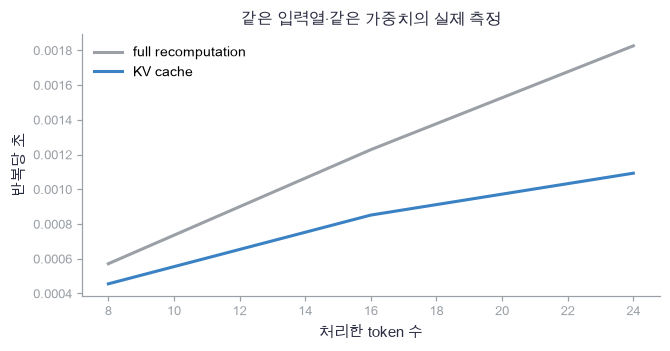

In [53]:
plot_cache_timing(budget_lengths,timing_results)

🔍 **확인** · 시간 측정은 같은 가중치·예정 token열로 반복하여 EOS 길이 차이를 제거했습니다. 두 경로 모두 첫 token 처리를 포함합니다. 장비·BLAS·호출 순서·시스템 상태가 영향을 주므로 한 측정의 비율을 보편적 속도 보장으로 보고하지 않습니다.

이 구조는 [Transformer 원문](https://arxiv.org/abs/1706.03762)의 Q/K/V·causal 계산을 작은 한 block으로 옮긴 것입니다. cache는 그 고정 계산의 대수적 재사용입니다. 다음47번의 양방향 encoder에서는 새 token이 과거 표현도 바꿀 수 있어 이 causal 재사용 논리를 그대로 적용하지 않습니다.

### ✏️ 연습 5 · 같은 난수의 동일 결과 확인하기

full과 cached 두 정수목록이 같은 same을 채우세요.

In [54]:
def exercise_same(full, cached):
    """같은 난수의 동일 결과 확인하기의 계산을 완성합니다."""
    ### 구현할 내용: full과 cached 두 정수목록이 같은 same을 채우세요.
    raise NotImplementedError
    return same

In [55]:
def check_same(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    assert candidate([1,3,2],[1,3,2]), '같은 token열입니다'
    assert not candidate([1,3,2],[1,4,2]), '중간token이 다르면 같은 결과가 아닙니다'
    print("연습 5 통과")

run_check(check_same, exercise_same, hint="같은 난수의 동일 결과 확인하기의 수식과 축을 확인하세요.")

☐ exercise_same: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 같은 난수의 동일 결과 확인하기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
same = full == cached
```

</details>

## ✏️ 끝 연습 · A–D

분포·계산·메모리의 규약을 각각 바꿔 봅니다.

### ✏️ 연습 A · temperature의 안정적인 지수

logits의 최대값을 빼고 temperature로 나눈 exponential을 채우세요.

In [56]:
def exercise_temperature(logits, temperature):
    """temperature의 안정적인 지수의 계산을 완성합니다."""
    ### 구현할 내용: logits의 최대값을 빼고 temperature로 나눈 exponential을 채우세요.
    raise NotImplementedError
    return exponential

In [57]:
def check_temperature(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_allclose(candidate(np.array([1000.,999.]),1.),[1.,np.exp(-1)])  # 검산: 넘침 없이 점수 차이만 사용
    print("연습 A 통과")

run_check(check_temperature, exercise_temperature, hint="temperature의 안정적인 지수의 수식과 축을 확인하세요.")

☐ exercise_temperature: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: temperature의 안정적인 지수의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
exponential = np.exp((logits - logits.max()) / temperature)
```

</details>

### ✏️ 연습 B · top-p 경계 token 포함하기

정렬된 p의 이전 누적질량으로 keep을 채우세요.

In [58]:
def exercise_nucleus(p, threshold):
    """top-p 경계 token 포함하기의 계산을 완성합니다."""
    ### 구현할 내용: 정렬된 p의 이전 누적질량으로 keep을 채우세요.
    raise NotImplementedError
    return keep

In [59]:
def check_nucleus(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_array_equal(candidate(np.array([.5,.3,.2]),.7),[1,1,0])  # 검산: .7을 처음 넘기는 둘째까지
    print("연습 B 통과")

run_check(check_nucleus, exercise_nucleus, hint="top-p 경계 token 포함하기의 수식과 축을 확인하세요.")

☐ exercise_nucleus: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: top-p 경계 token 포함하기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
keep = (np.cumsum(p) - p) < threshold
```

</details>

### ✏️ 연습 C · cache에 새 행을 붙이기

old와 new_row를 위치축으로 이어 combined를 채우세요.

In [60]:
def exercise_append(old, new_row):
    """cache에 새 행을 붙이기의 계산을 완성합니다."""
    ### 구현할 내용: old와 new_row를 위치축으로 이어 combined를 채우세요.
    raise NotImplementedError
    return combined

In [61]:
def check_append(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_array_equal(candidate(np.array([[1,2]]),np.array([[3,4]])),[[1,2],[3,4]])  # 검산: 위치 순서 보존
    print("연습 C 통과")

run_check(check_append, exercise_append, hint="cache에 새 행을 붙이기의 수식과 축을 확인하세요.")

☐ exercise_append: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: cache에 새 행을 붙이기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
combined = np.concatenate([old, new_row], axis=0)
```

</details>

### ✏️ 연습 D · cache score 계산량 더하기

1부터 length까지 새 query의 key 수 합 total을 구하세요.

In [62]:
def exercise_cost(length):
    """cache score 계산량 더하기의 계산을 완성합니다."""
    ### 구현할 내용: 1부터 length까지 새 query의 key 수 합 total을 구하세요.
    raise NotImplementedError
    return total

In [63]:
def check_cost(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    assert candidate(4)==10, '1+2+3+4=10입니다'
    print("연습 D 통과")

run_check(check_cost, exercise_cost, hint="cache score 계산량 더하기의 수식과 축을 확인하세요.")

☐ exercise_cost: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: cache score 계산량 더하기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
total = length * (length + 1) // 2
```

</details>

## ✏️ 준비도 · 설명·수식·구현·변형 검산

- **설명:** 생성 정책의 변경과 cache의 계산 재사용을 구분하고, 왜 학습 가중치가 바뀌면 cache를 버려야 하는지 말할 수 있나요?
- **수식:** top-p의 경계 token 포함, 현재 query의 `(1,T)` 점수, 두 K/V 배열의 byte 수를 적을 수 있나요?
- **구현:** prefill의 K/V와 다음 위치를 정확히 넘기고 같은 uniform으로 full/cache 생성 전체를 대조할 수 있나요?
- **변형 검산:** 동률·영확률·극단 logits·즉시 EOS·미종료·위치 상한·다른 prefix 길이에서도 규약이 유지되는지 확인할 수 있나요?